# Stage 3 – Verification and Performance of the CO2 Solvers

**MMA3001 Project – Occupancy-driven ventilation assessment (Tom Gregory)**

This notebook checks that the numerical methods in `occvent` solve the CO2 model correctly, and measures how much each one costs. It is the evidence for the brief's **Validation** (§5) and **Optimisation and performance** (§6) sections.

The CO2 model is the same kind of equation as the heated thermal mass in MMA3001 Notebook 7.2: one well-mixed state, one time constant, and an input that changes in steps:

$$V\frac{dC}{dt} = 10^6 G\,N(t) + Q\,(C_{out}-C) \quad\Longleftrightarrow\quad \frac{dC}{dt} = a - kC,\qquad k=\frac{Q}{V}.$$

Because the occupancy $N$ is constant within each 1-minute step, the **exact solution** is known on every step. That gives a perfect reference to measure every solver against.

| Section | Question answered | Course link |
|---|---|---|
| A | Set-up: data, parameters, test problems | 7.2 |
| B | Does each solver converge at its theoretical order? | 7.3.7, 7.4.7 |
| C | Do the *engineering answers* converge? How coarse can the input data be? | 7.3.17, brief §6 |
| D | Accuracy versus cost (right-hand-side evaluations) | 7.4.6, 7.4.12 |
| E | Stability: when does each method blow up? | 7.3.8, 7.4.8, 9.1, 9.3 |
| F | Is the problem stiff? | 9.2 |
| G | Exact time-averaging versus the trapezoidal rule | 6.1, 6.2 |
| H | Why resample with a zero-order hold and not linear interpolation? | 3.1 |
| I | Numerical error versus model (parameter) error | 7.2.13 |
| J | Performance: timing, profiling, FLOPs, arithmetic intensity, roofline | 2.1 |
| K | Summary | |

**Verification vs validation (Notebook 7.2.13).** This notebook *verifies* that the equations are solved correctly. It does not show that the room's real CO2 follows the model; no CO2 measurements exist (see the project definition).

**Before running:** build the processed data once from the repository root with `python -m occvent.prepare --raw data/raw/5occupancySensor_MayToDec2024_9MRows.zip`. Section H also reads the raw zip directly. Running the whole notebook takes about 1–2 minutes.

## A. Set-up

In [1]:
import cProfile
import io
import pstats
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Locate the repository root whether the notebook is run from notebooks/ or the root.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
try:
    import occvent
except ImportError:  # package not installed with `pip install -e .`
    sys.path.insert(0, str(ROOT / "src"))
    import occvent

from occvent.cleaning import ResampleSettings, clean_events, resample_occupancy
from occvent.co2model import (RoomParameters, exact_solution, occupancy_from_grid,
                              step_mean_concentration)
from occvent.config import ESTIMATED_VOLUME_M3, LOCAL_TIMEZONE, get_room
from occvent.io import load_processed, read_occupancy_events
from occvent.metrics import compliance_metrics, rolling_mean
from occvent.solvers import SOLVERS, explicit_euler, implicit_euler, rk4, solve_scipy
from occvent.verification import (FLOPS_PER_SUBSTEP, STABILITY_LIMIT, arithmetic_intensity,
                                  best_time, convergence_study, empirical_roofline,
                                  observed_orders, stability_function, stiffness_summary)

PROCESSED = ROOT / "data" / "processed" / "G20_occupancy_1min.csv.gz"
RAW = ROOT / "data" / "raw" / "5occupancySensor_MayToDec2024_9MRows.zip"
FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
if not PROCESSED.exists():
    raise FileNotFoundError(f"{PROCESSED} not found. Run `python -m occvent.prepare --raw {RAW}` first.")

# Consistent, colour-blind-checked colours and markers per method (identity never by colour alone).
STYLE = {
    "exact":          dict(color="#0b0b0b", marker="",  ls="-",  label="Exact"),
    "explicit_euler": dict(color="#2a78d6", marker="o", ls="-",  label="Explicit Euler"),
    "implicit_euler": dict(color="#eb6834", marker="s", ls="--", label="Implicit Euler"),
    "rk4":            dict(color="#1baf7a", marker="^", ls="-.", label="RK4"),
    "scipy_rk45":     dict(color="#eda100", marker="D", ls=":",  label="SciPy RK45"),
    "scipy_lsoda":    dict(color="#e87ba4", marker="v", ls=":",  label="SciPy LSODA"),
}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "lines.linewidth": 2, "lines.markersize": 7})

def save(fig, name):
    # Save a figure for the report as well as showing it here.
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("occvent version", occvent.__version__)

occvent version 0.2.0


In [2]:
# Full G.20 record (1-minute bins) and the busiest week in it (Mon 16 - Sun 22 Sep 2024, local time).
grid = load_processed(PROCESSED)
occ_all, DT, n_filled = occupancy_from_grid(grid)          # DT = 60 s; G.20 needs no gap filling
local = grid.index.tz_convert(LOCAL_TIMEZONE)
week_mask = (local >= pd.Timestamp("2024-09-16", tz=LOCAL_TIMEZONE)) & (local < pd.Timestamp("2024-09-23", tz=LOCAL_TIMEZONE))
occ_week = occ_all[week_mask]
t_week = local[week_mask]

# Realistic G.20 parameters. V is ESTIMATED (no dimensions available). Q is illustrative here
# (10 L/s per person x 30 people); Stage 4 determines the design and minimum rates properly.
P_REAL = RoomParameters(volume_m3=ESTIMATED_VOLUME_M3["G20"])
Q_REAL = 300.0

# "Stress" test problem: same real occupancy, small room with strong ventilation, so k*dt = 0.5
# and solver errors are large enough to measure their convergence clearly.
P_TEST = RoomParameters(volume_m3=100.0)
Q_TEST = 0.5 / DT * P_TEST.volume_m3 * 1000.0               # L/s giving k*dt = 0.5

print(f"Full record : {occ_all.size:,} one-minute steps ({occ_all.size/1440:.0f} days), filled bins = {n_filled}")
print(f"Test week   : {occ_week.size:,} steps, {t_week[0]:%a %d %b %Y} to {t_week[-1]:%a %d %b %Y}, "
      f"mean {occ_week.mean():.2f} people, max {occ_week.max():.1f}")
print(f"Real params : V = {P_REAL.volume_m3:.0f} m3, Q = {Q_REAL:.0f} L/s -> k*dt = {Q_REAL/1000/P_REAL.volume_m3*DT:.3f}")
print(f"Test params : V = {P_TEST.volume_m3:.0f} m3, Q = {Q_TEST:.1f} L/s -> k*dt = {Q_TEST/1000/P_TEST.volume_m3*DT:.3f}")

Full record : 1,123,729 one-minute steps (780 days), filled bins = 0
Test week   : 10,080 steps, Mon 16 Sep 2024 to Sun 22 Sep 2024, mean 3.34 people, max 22.4
Real params : V = 600 m3, Q = 300 L/s -> k*dt = 0.030
Test params : V = 100 m3, Q = 833.3 L/s -> k*dt = 0.500


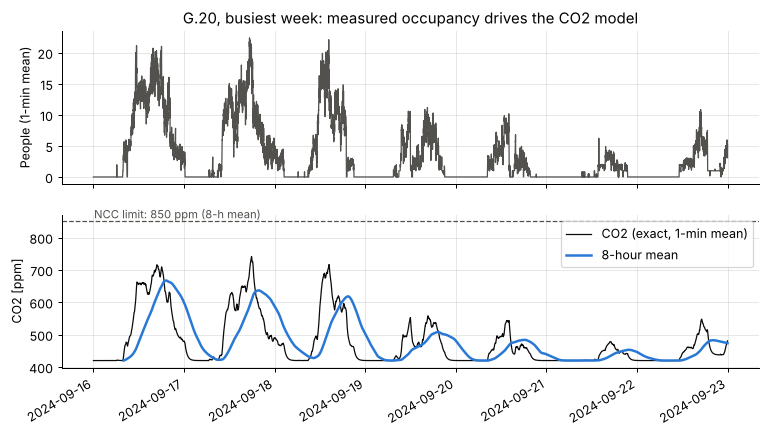

In [3]:
# Exact CO2 for the real week, to see what the solvers must reproduce.
c_week = exact_solution(occ_week, Q_REAL, P_REAL, DT)
mean_week = step_mean_concentration(c_week, occ_week, Q_REAL, P_REAL, DT)
r8 = rolling_mean(mean_week, int(8 * 3600 / DT))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
ax1.plot(t_week, occ_week, color="#52514e", lw=1)
ax1.set_ylabel("People (1-min mean)")
ax1.set_title("G.20, busiest week: measured occupancy drives the CO2 model")
ax2.plot(t_week, mean_week, color=STYLE["exact"]["color"], lw=1, label="CO2 (exact, 1-min mean)")
ax2.plot(t_week, r8, color=STYLE["explicit_euler"]["color"], lw=2, label="8-hour mean")
ax2.axhline(850, color="#52514e", ls="--", lw=1)
ax2.text(t_week[10], 860, "NCC limit: 850 ppm (8-h mean)", fontsize=9, color="#52514e")
ax2.set_ylabel("CO2 [ppm]")
ax2.legend(loc="upper right")
fig.autofmt_xdate()
save(fig, "stage3_week_overview")

## B. Convergence: does each solver reach its theoretical order?

Each fixed-step solver is run with $m$ sub-steps per 1-minute data step ($h = 60/m$ s) and compared with the exact solution. If the global error behaves like $E \approx C h^p$, the **observed order** between two step sizes is (Notebook 7.3.7)

$$p_{obs} = \frac{\log(E_1/E_2)}{\log(h_1/h_2)}.$$

Theory: explicit and implicit Euler are first order ($p = 1$); classical RK4 is fourth order ($p = 4$). Sub-steps never cross a change in occupancy (the event-alignment rule, Notebook 7.3.10), so the forcing is smooth inside every sub-step and the theoretical orders should appear.


Explicit Euler
 substeps    h_s       kh  max_abs_error_ppm  observed_order  rhs_evaluations
        1     60      0.5              33.01             NaN            10080
        2     30     0.25              14.41           1.195            20160
        4     15    0.125              6.796           1.085            40320
        8    7.5   0.0625              3.305            1.04            80640
       16   3.75  0.03125              1.631           1.019           161280
       32  1.875  0.01562               0.81            1.01           322560
       64 0.9375 0.007812             0.4037           1.005           645120

Implicit Euler
 substeps    h_s       kh  max_abs_error_ppm  observed_order  rhs_evaluations
        1     60      0.5              21.44             NaN            10080
        2     30     0.25              11.68          0.8759            20160
        4     15    0.125              6.122          0.9321            40320
        8    7.5   0.0625       

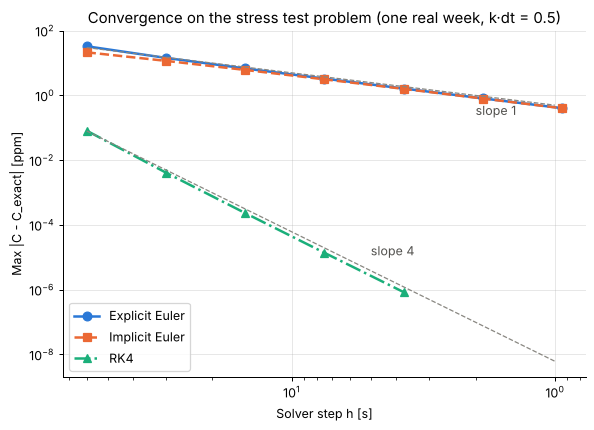

In [4]:
studies = {}
for name, m_list in [("explicit_euler", [1, 2, 4, 8, 16, 32, 64]),
                     ("implicit_euler", [1, 2, 4, 8, 16, 32, 64]),
                     ("rk4",            [1, 2, 4, 8, 16])]:      # finer RK4 steps hit round-off
    studies[name] = convergence_study(name, occ_week, Q_TEST, P_TEST, DT, m_list, c0_ppm=700.0)

fig, ax = plt.subplots(figsize=(7.5, 5))
for name, df in studies.items():
    s = STYLE[name]
    ax.loglog(df["h_s"], df["max_abs_error_ppm"], color=s["color"], marker=s["marker"], ls=s["ls"], label=s["label"])
h_ref = np.array([60, 1])
ax.loglog(h_ref, 30 * (h_ref / 60) ** 1, color="#898781", lw=1, ls="--")
ax.loglog(h_ref, 0.08 * (h_ref / 60) ** 4, color="#898781", lw=1, ls="--")
ax.text(2.0, 30 * (2 / 60) * 0.25, "slope 1", color="#52514e")
ax.text(5.0, 0.08 * (5 / 60) ** 4 * 3, "slope 4", color="#52514e")
ax.set_xlabel("Solver step h [s]")
ax.set_ylabel("Max |C - C_exact| [ppm]")
ax.set_title("Convergence on the stress test problem (one real week, k·dt = 0.5)")
ax.invert_xaxis()
ax.legend()
save(fig, "stage3_convergence")

for name, df in studies.items():
    print(f"\n{STYLE[name]['label']}")
    print(df[["substeps", "h_s", "kh", "max_abs_error_ppm", "observed_order", "rhs_evaluations"]]
          .to_string(index=False, float_format=lambda v: f"{v:.4g}"))

In [5]:
# The same solvers with the realistic G.20 parameters (k*dt = 0.03) and the 1-minute data step:
# errors are tiny because the step is 1/33 of the 33-minute time constant.
rows = []
for name in ["explicit_euler", "implicit_euler", "rk4"]:
    df = convergence_study(name, occ_week, Q_REAL, P_REAL, DT, [1, 2, 4])
    rows.append({"method": STYLE[name]["label"], "max error @ h=60 s [ppm]": df["max_abs_error_ppm"][0],
                 "observed order (h=15 s)": df["observed_order"].iloc[-1]})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))

        method  max error @ h=60 s [ppm]  observed order (h=15 s)
Explicit Euler                      1.04                        1
Implicit Euler                      1.02                    0.996
           RK4                  4.76e-07                     4.01


**What this shows.** On the log–log plot each method's error falls along a straight line of the expected slope: 1 for both Euler methods, 4 for RK4. The tables confirm observed orders tending to 1, 1 and 4. RK4 stops at $h = 3.75$ s because by then its error is near the floating-point round-off level (Notebook 7.4.7 warns that order must be read from the straight-line region only).

With realistic G.20 parameters the 1-minute data step is already very small compared with the room's 33-minute time constant. Even explicit Euler is accurate to a few ppm there.

## C. Do the engineering answers converge? And how coarse can the input data be?

Notebook 7.3.17: *"Refine h and quantify convergence of decision-relevant outputs."* The outputs that matter here are the **maximum 8-hour mean** (NCC limit 850 ppm), the **peak**, and the **time above 1000 ppm**.

There are two separate effects:

1. **Solver step** $h$: refining the solver on the same 1-minute input.
2. **Input resolution**: averaging the occupancy to coarser bins (5–60 min) before simulating. This keeps person-time, but smooths out short busy periods. Brief §6 lists "input resolution" as a performance trade-off.

In [6]:
def metrics_from(c_grid, occ, q, p, dt):
    # Decision-relevant outputs from grid values of C (exact step means are used for averaging).
    return compliance_metrics(step_mean_concentration(c_grid, occ, q, p, dt), dt)

ref = metrics_from(c_week, occ_week, Q_REAL, P_REAL, DT)
rows = []
for name in ["explicit_euler", "implicit_euler", "rk4"]:
    for m in [1, 2, 4, 8]:
        c = SOLVERS[name](occ_week, Q_REAL, P_REAL, DT, substeps=m)
        # Solver grid values are averaged with the exact step-mean formula so only solver error differs.
        mt = metrics_from(c, occ_week, Q_REAL, P_REAL, DT)
        rows.append({"method": STYLE[name]["label"], "h [s]": DT / m,
                     "max 8-h mean [ppm]": mt["max_8h_mean_ppm"],
                     "error in max 8-h mean [ppm]": abs(mt["max_8h_mean_ppm"] - ref["max_8h_mean_ppm"]),
                     "peak [ppm]": mt["peak_ppm"],
                     "error in peak [ppm]": abs(mt["peak_ppm"] - ref["peak_ppm"])})
print(f"Exact: max 8-h mean = {ref['max_8h_mean_ppm']:.2f} ppm, peak = {ref['peak_ppm']:.1f} ppm, "
      f"time above 1000 ppm = {100*ref['fraction_above_peak_limit']:.2f} %\n")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))

Exact: max 8-h mean = 667.51 ppm, peak = 741.6 ppm, time above 1000 ppm = 0.00 %

        method  h [s]  max 8-h mean [ppm]  error in max 8-h mean [ppm]  peak [ppm]  error in peak [ppm]
Explicit Euler     60                 668                        0.094         742                 0.61
Explicit Euler     30                 668                       0.0471         742                0.302
Explicit Euler     15                 668                       0.0236         742                0.151
Explicit Euler    7.5                 668                       0.0118         742               0.0752
Implicit Euler     60                 667                       0.0942         741                0.596
Implicit Euler     30                 667                       0.0473         741                0.299
Implicit Euler     15                 667                       0.0236         741                 0.15
Implicit Euler    7.5                 668                       0.0118         741    

 input bin [min]  max 8-h mean [ppm]  peak [ppm]  time > 1000 ppm [%]  person-hours
               1               667.5       741.6                    0         560.5
               5               667.5       739.8                    0         560.5
              15               667.3         733                    0         560.5
              30               666.1       723.2                    0         560.5
              60               664.6       703.2                    0         560.5


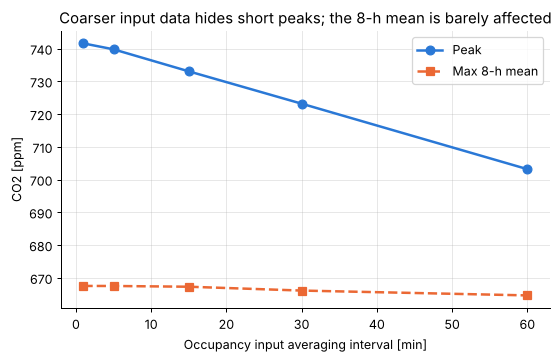

In [7]:
# Input resolution: average the 1-minute occupancy into coarser bins, then solve exactly.
# Exact solving isolates the effect of the input data from any solver error.
res_rows = []
for bin_min in [1, 5, 15, 30, 60]:
    k = bin_min
    n_use = (occ_week.size // k) * k
    occ_coarse = occ_week[:n_use].reshape(-1, k).mean(axis=1)    # conserves person-time
    dt_c = DT * k
    c = exact_solution(occ_coarse, Q_REAL, P_REAL, dt_c)
    mt = compliance_metrics(step_mean_concentration(c, occ_coarse, Q_REAL, P_REAL, dt_c), dt_c)
    res_rows.append({"input bin [min]": bin_min, "max 8-h mean [ppm]": mt["max_8h_mean_ppm"],
                     "peak [ppm]": mt["peak_ppm"],
                     "time > 1000 ppm [%]": 100 * mt["fraction_above_peak_limit"],
                     "person-hours": occ_coarse.sum() * dt_c / 3600})
res = pd.DataFrame(res_rows)
print(res.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(res["input bin [min]"], res["peak [ppm]"], color=STYLE["explicit_euler"]["color"], marker="o", label="Peak")
ax.plot(res["input bin [min]"], res["max 8-h mean [ppm]"], color=STYLE["implicit_euler"]["color"], marker="s", ls="--", label="Max 8-h mean")
ax.set_xlabel("Occupancy input averaging interval [min]")
ax.set_ylabel("CO2 [ppm]")
ax.set_title("Coarser input data hides short peaks; the 8-h mean is barely affected")
ax.legend()
save(fig, "stage3_input_resolution")

**What this shows.** With the 1-minute data step, every solver's error in the maximum 8-hour mean is far below 1 ppm. With the illustrative 300 L/s, this week never exceeds 1000 ppm, so that metric is 0 for every method. That is negligible against an 850 ppm limit, so the compliance decision does not depend on the solver choice. The peak is slightly more sensitive than the 8-hour mean, as expected, since averaging cancels errors.

Coarsening the **input data** matters more than the solver. Person-hours are conserved exactly, so the 8-hour mean hardly moves. But the peak falls as short crowds are averaged away. Keeping the full 1-minute resolution is therefore justified for any peak-based criterion. It costs nothing extra with the exact solver.

## D. Accuracy versus cost

Notebook 7.4.6: one fixed step costs 1 right-hand-side (RHS) evaluation for Euler and 4 for RK4. A higher-order method is worth it when its error reduction outweighs the extra cost. SciPy's adaptive solvers are included with a range of tolerances `rtol` (`atol = 100 × rtol` ppm), counting the evaluations they report (`nfev`). One busy day of the stress test problem is used to keep SciPy's run time short.

Data steps in the day: 1440. SciPy must take at least one step per data step (max_step = dt).


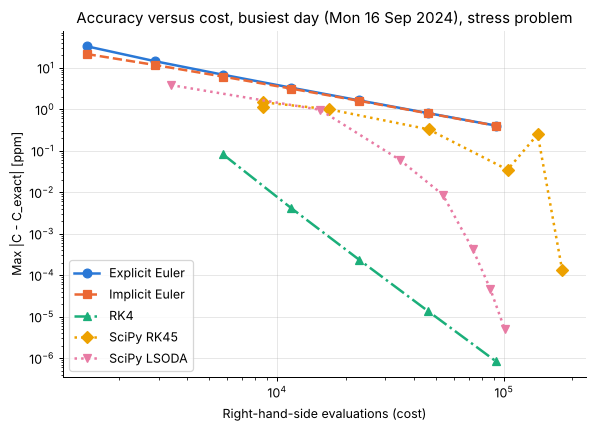

In [8]:
day_local = t_week.normalize()
busiest_day = pd.Series(occ_week).groupby(day_local).sum().idxmax()
day_mask = np.asarray(day_local == busiest_day)
occ_day = occ_week[day_mask]
ref_day = exact_solution(occ_day, Q_TEST, P_TEST, DT, c0_ppm=700.0)

work = {}
for name, m_list in [("explicit_euler", [1, 2, 4, 8, 16, 32, 64]), ("implicit_euler", [1, 2, 4, 8, 16, 32, 64]),
                     ("rk4", [1, 2, 4, 8, 16])]:
    df = convergence_study(name, occ_day, Q_TEST, P_TEST, DT, m_list, c0_ppm=700.0)
    work[name] = (df["rhs_evaluations"].to_numpy(), df["max_abs_error_ppm"].to_numpy())
for method, key in [("RK45", "scipy_rk45"), ("LSODA", "scipy_lsoda")]:
    nfev, err = [], []
    for rtol in [1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8, 1e-9]:
        c, info = solve_scipy(occ_day, Q_TEST, P_TEST, DT, c0_ppm=700.0, method=method,
                              rtol=rtol, atol=100 * rtol, full_output=True)
        nfev.append(info["nfev"]); err.append(np.max(np.abs(c - ref_day)))
    work[key] = (np.array(nfev), np.array(err))

fig, ax = plt.subplots(figsize=(7.5, 5))
for key, (n, e) in work.items():
    s = STYLE[key]
    ax.loglog(n, e, color=s["color"], marker=s["marker"], ls=s["ls"], label=s["label"])
ax.set_xlabel("Right-hand-side evaluations (cost)")
ax.set_ylabel("Max |C - C_exact| [ppm]")
ax.set_title(f"Accuracy versus cost, busiest day ({busiest_day:%a %d %b %Y}), stress problem")
ax.legend()
save(fig, "stage3_work_precision")
print(f"Data steps in the day: {occ_day.size}. SciPy must take at least one step per data step (max_step = dt).")

**What this shows.** For any given accuracy, RK4 needs far fewer evaluations than either Euler method: the RK4 curve sits lowest and furthest left. SciPy's adaptive solvers are reliable but expensive here. RK45's achieved error is not even monotonic in its tolerance, because a tolerance controls an estimated *local* error, not the global error plotted (Notebook 7.4.12). The input changes every minute, so the step-size controller must "discover" each jump in occupancy and can never take a step longer than one minute. Adaptive stepping pays off for smooth problems, not for this one. The exact solution costs one exponential per step and has no discretisation error at all, which is why it is the method used for the engineering analyses.

## E. Stability

Applied to the decay test equation $y' = -\lambda y$ with $r = \lambda h$, one step multiplies the solution by the **stability function** $R(-r)$ (Notebooks 7.3.8, 7.4.8, 9.3):

| Method | $R(-r)$ | Stable when |
|---|---|---|
| Explicit Euler | $1-r$ | $r < 2$ (oscillates for $1<r<2$) |
| RK4 | $1-r+\tfrac{r^2}{2}-\tfrac{r^3}{6}+\tfrac{r^4}{24}$ | $r < 2.785$ |
| Implicit Euler | $1/(1+r)$ | always (unconditionally stable) |
| Exact | $e^{-r}$ | always |

For the CO2 model $\lambda = k = Q/V$, so $r = kh = h/\tau$.

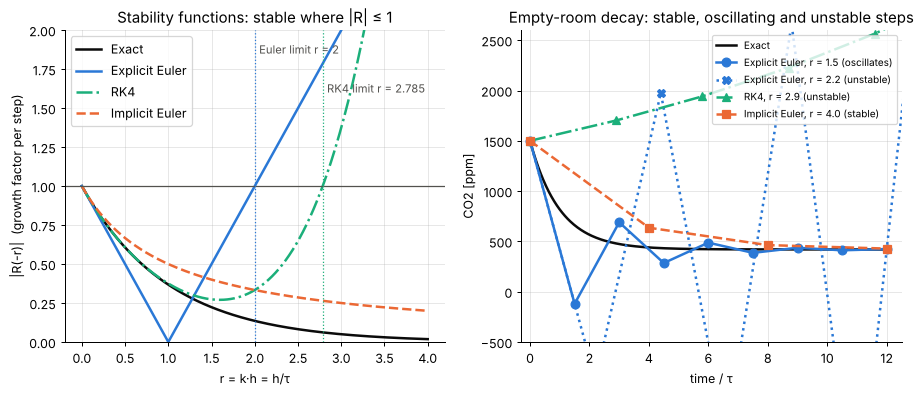

In [9]:
r = np.linspace(0, 4, 401)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for name in ["exact", "explicit_euler", "rk4", "implicit_euler"]:
    s = STYLE[name]
    ax1.plot(r, np.abs(stability_function(name, r)), color=s["color"], ls=s["ls"], label=s["label"])
ax1.axhline(1, color="#52514e", lw=1)
for name, txt, y in [("explicit_euler", "Euler limit r = 2", 1.85), ("rk4", "RK4 limit r = 2.785", 1.6)]:
    ax1.axvline(STABILITY_LIMIT[name], color=STYLE[name]["color"], lw=1, ls=":")
    ax1.text(STABILITY_LIMIT[name] + 0.05, y, txt, color="#52514e", fontsize=9)
ax1.set_ylim(0, 2)
ax1.set_xlabel("r = k·h = h/τ")
ax1.set_ylabel("|R(-r)|  (growth factor per step)")
ax1.set_title("Stability functions: stable where |R| ≤ 1")
ax1.legend(loc="upper left")

# Empty-room decay from 1500 ppm with the stress parameters (tau = 120 s), at several step ratios.
tau = P_TEST.volume_m3 / (Q_TEST / 1000)
t_end = 12 * tau
t_fine = np.linspace(0, t_end, 400)
ax2.plot(t_fine / tau, 420 + 1080 * np.exp(-t_fine / tau), color=STYLE["exact"]["color"], label="Exact")
for name, rr, mk, ls in [("explicit_euler", 1.5, "o", "-"), ("explicit_euler", 2.2, "X", ":"),
                         ("rk4", 2.9, "^", "-."), ("implicit_euler", 4.0, "s", "--")]:
    h = rr * tau
    n = int(np.ceil(t_end / h))
    c = SOLVERS[name](np.zeros(n), Q_TEST, P_TEST, h, c0_ppm=1500.0)
    s = STYLE[name]
    ax2.plot(np.arange(n + 1) * h / tau, c, color=s["color"], marker=mk, ls=ls,
             label=f"{s['label']}, r = {rr}" + (" (oscillates)" if rr == 1.5 else " (unstable)" if name != "implicit_euler" else " (stable)"))
ax2.set_ylim(-500, 2600)
ax2.set_xlim(-0.3, 12.5)
ax2.set_xlabel("time / τ")
ax2.set_ylabel("CO2 [ppm]")
ax2.set_title("Empty-room decay: stable, oscillating and unstable steps")
ax2.legend(fontsize=8, loc="upper right")
save(fig, "stage3_stability")

**What this shows.** Explicit Euler at $r = 1.5$ is *stable but oscillatory*: it converges while overshooting below the outdoor level, which is physically impossible (Notebook 7.3.9). At $r = 2.2$ it grows without bound. RK4 survives to $r \approx 2.785$ and fails beyond it ($r = 2.9$ shown). Implicit Euler decays monotonically even at $r = 4$, although it is inaccurate at that step, because stability is not accuracy. For G.20 at realistic ventilation, $r = 0.03$ per minute, a factor of about 60 inside Euler's limit.

## F. Is the problem stiff?

A **stiff** ODE contains widely different time scales, so stability (the fastest scale) forces a far smaller step than accuracy (the slow scale) needs (Notebook 9.2). The single-zone CO2 model has **one** eigenvalue, $\lambda = -Q/V$, so its stiffness ratio is 1: **it is not stiff.**

Stability can still matter when the *data step* is long compared with the time constant: for example, a small, strongly ventilated meeting room logged every 15 minutes. That is when implicit Euler (or the exact solution) is the safe choice.

In [10]:
cases = {"G.20 (V=600 m3, Q=300 L/s), 1-min data": (Q_REAL, P_REAL.volume_m3, 60.0),
         "G.20, hourly data": (Q_REAL, P_REAL.volume_m3, 3600.0),
         "Small meeting room (V=30 m3, Q=300 L/s), 1-min data": (300.0, 30.0, 60.0),
         "Small meeting room, 15-min data": (300.0, 30.0, 900.0)}
rows = []
for label, (q, v, dt) in cases.items():
    s = stiffness_summary(q, v, dt)
    rows.append({"case": label, "τ [min]": s["time_constant_s"] / 60, "ACH [1/h]": s["air_changes_per_hour"],
                 "k·dt": s["k_dt"], "Euler stable?": s["k_dt"] < 2,
                 "RK4 stable?": s["k_dt"] < STABILITY_LIMIT["rk4"], "stiffness ratio": s["stiffness_ratio"]})
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))

# Demonstrate the last case: one day of real occupancy, aggregated to 15-min steps, in a 30 m3 room.
p_small = RoomParameters(volume_m3=30.0)
occ15 = occ_day[: (occ_day.size // 15) * 15].reshape(-1, 15).mean(axis=1)
exact15 = exact_solution(occ15, 300.0, p_small, 900.0)
for name in ["explicit_euler", "rk4", "implicit_euler"]:
    c = SOLVERS[name](occ15, 300.0, p_small, 900.0)
    print(f"{STYLE[name]['label']:15s} 15-min steps: max |error| = {np.max(np.abs(c - exact15)):.3g} ppm, "
          f"min C = {c.min():.3g} ppm (outdoor = 420)")

                                               case  τ [min]  ACH [1/h]  k·dt  Euler stable?  RK4 stable?  stiffness ratio
             G.20 (V=600 m3, Q=300 L/s), 1-min data     33.3        1.8  0.03           True         True                1
                                  G.20, hourly data     33.3        1.8   1.8           True         True                1
Small meeting room (V=30 m3, Q=300 L/s), 1-min data     1.67         36   0.6           True         True                1
                    Small meeting room, 15-min data     1.67         36     9          False        False                1
Explicit Euler  15-min steps: max |error| = 4.11e+65 ppm, min C = -4.11e+65 ppm (outdoor = 420)
RK4             15-min steps: max |error| = 4.66e+163 ppm, min C = -4.66e+163 ppm (outdoor = 420)
Implicit Euler  15-min steps: max |error| = 9.34 ppm, min C = 420 ppm (outdoor = 420)


**What this shows.** For G.20, explicit Euler stays stable even with hourly data ($k\,dt = 1.8 < 2$), although it would oscillate ($k\,dt > 1$). For a small, well-ventilated room with 15-minute data ($k\,dt = 9$), explicit Euler and RK4 blow up to absurd values, while implicit Euler stays bounded and physically sensible. The model is not stiff in the multi-scale sense of Notebook 9.2. The limit comes from the data spacing relative to a single time constant.

## G. Exact time-averaging versus the trapezoidal rule

The NCC criterion is an 8-hour *time average*, i.e. an integral $\frac{1}{8\,\mathrm{h}}\int C\,dt$. The project computes each step's integral exactly from the step solution (`step_mean_concentration`). The common alternative is to sample $C$ every $s$ minutes and apply the **composite trapezoidal rule** (Notebook 6.1). Its error should fall as $s^2$ for a smooth integrand. But $C(t)$ has a *corner* wherever occupancy jumps, which can reduce the observed order (Notebook 6.2.9).

Exact max 8-h mean: 667.5133 ppm
 sample interval s [min]  trapezoid max 8-h mean [ppm]  error [ppm]  observed order
                       1                         667.5    5.559e-06             NaN
                       2                         667.5      0.00951           10.74
                       4                         667.5      0.01499           0.656
                       8                         667.4       0.1211           3.015
                      16                         667.3       0.2467           1.026
                      32                         666.8       0.7156           1.537
                      60                         665.8        1.676           1.354


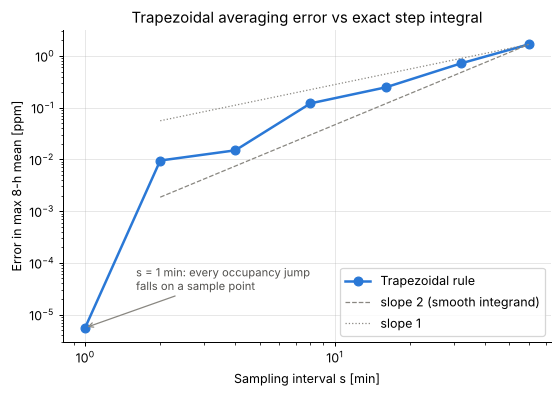

In [11]:
exact_max8 = ref["max_8h_mean_ppm"]
trap_rows = []
for s_min in [1, 2, 4, 8, 16, 32, 60]:
    sampled = c_week[::s_min]                                # C every s minutes (grid values)
    panel = 0.5 * (sampled[:-1] + sampled[1:])               # trapezoid mean of each s-minute panel
    w = int(480 / s_min) if 480 % s_min == 0 else None
    if w is None:
        continue
    max8 = np.nanmax(rolling_mean(panel, w))
    trap_rows.append({"sample interval s [min]": s_min, "trapezoid max 8-h mean [ppm]": max8,
                      "error [ppm]": abs(max8 - exact_max8)})
trap = pd.DataFrame(trap_rows)
trap["observed order"] = np.concatenate(([np.nan], observed_orders(trap.iloc[:, 0], trap["error [ppm]"])))
print(f"Exact max 8-h mean: {exact_max8:.4f} ppm")
print(trap.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.loglog(trap.iloc[:, 0], trap["error [ppm]"], color=STYLE["explicit_euler"]["color"], marker="o", label="Trapezoidal rule")
s_ref = np.array([2.0, 60.0])
e_last = trap["error [ppm]"].iloc[-1]
ax.loglog(s_ref, e_last * (s_ref / 60) ** 2, color="#898781", lw=1, ls="--", label="slope 2 (smooth integrand)")
ax.loglog(s_ref, e_last * (s_ref / 60) ** 1, color="#898781", lw=1, ls=":", label="slope 1")
ax.annotate("s = 1 min: every occupancy jump\nfalls on a sample point", xy=(1, trap["error [ppm]"].iloc[0]),
            xytext=(1.6, 3e-5), fontsize=9, color="#52514e", arrowprops=dict(arrowstyle="->", color="#898781"))
ax.set_xlabel("Sampling interval s [min]")
ax.set_ylabel("Error in max 8-h mean [ppm]")
ax.set_title("Trapezoidal averaging error vs exact step integral")
ax.legend()
save(fig, "stage3_trapezoid")

**What this shows.** At $s = 1$ minute the trapezoidal error is tiny (about $10^{-5}$ ppm). Every occupancy jump then falls exactly on a sample point, so each panel's integrand is smooth and the rule is second-order accurate. As soon as $s > 1$ minute, jumps (corners in $C$) fall *inside* panels. The error leaps by three orders of magnitude, and the observed order becomes irregular and closer to 1 than 2. That is precisely the warning of Notebook 6.2.9: a corner changes convergence. For example, sampling every 16–60 minutes misstates the 8-hour mean by about 0.25–1.7 ppm. The exact step integral has no such error and costs the same.

## H. Resampling: zero-order hold versus linear interpolation

The sensor writes a row only when the count changes. Between rows the true count is **constant**, so the correct reconstruction is a step function: a *zero-order hold* (ZOH), which is what `resample_occupancy` integrates exactly. Linear interpolation between event points (Notebook 3.1, a local interpolant) would draw ramps that never happened. This section quantifies the difference using the raw events of the busiest day.

Read and cleaned 1,894,867 raw events in 27.8 s
ZOH per-second vs resample_occupancy, max difference: 0.00e+00 people
Person-hours on 16 Sep 2024:  zero-order hold = 165.05,  linear interpolation = 173.63  (+5.20 %)
Peak CO2: ZOH 716.4 ppm, linear 716.5 ppm; max difference 32.4 ppm
Largest single invented ramp: 0 -> 1 people over 93 min = +0.77 person-hours


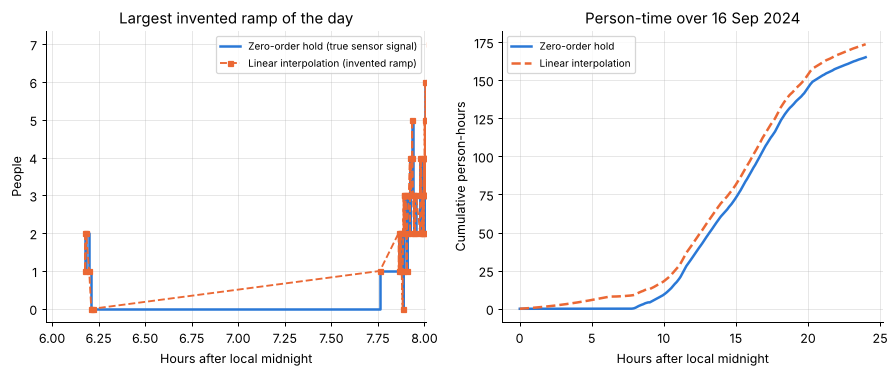

In [12]:
if not RAW.exists():
    print(f"Raw file not found at {RAW}; skipping section H.")
else:
    t0 = time.perf_counter()
    room = get_room("G20")
    raw = read_occupancy_events(RAW, [room.floorspace_id])
    events, _ = clean_events(raw)
    print(f"Read and cleaned {len(events):,} raw events in {time.perf_counter() - t0:.1f} s")

    day_start = busiest_day.tz_convert("UTC")
    day_end = day_start + pd.Timedelta(days=1)
    # Events from 3 h before to 3 h after the day, so both reconstructions are defined all day.
    ev = events[(events["t"] >= day_start - pd.Timedelta(hours=3))
                & (events["t"] < day_end + pd.Timedelta(hours=3))].reset_index(drop=True)
    secs = ((ev["t"] - day_start) / pd.Timedelta(seconds=1)).to_numpy()
    n_ev = ev["headcount"].to_numpy(dtype=float)

    # Evaluate both reconstructions at every second of the day (mid-second), then average per minute.
    t_sec = np.arange(0, 86400) + 0.5
    zoh_sec = n_ev[np.searchsorted(secs, t_sec, side="right") - 1]   # value of the latest event
    lin_sec = np.interp(t_sec, secs, n_ev)                           # straight line between events
    zoh_day = zoh_sec.reshape(1440, 60).mean(axis=1)
    lin_day = lin_sec.reshape(1440, 60).mean(axis=1)

    # Cross-check: the per-second ZOH equals the project's exact resampler on the same events.
    zoh_grid, _ = resample_occupancy(ev)
    lib_day = zoh_grid.loc[day_start:day_end - pd.Timedelta(minutes=1), "headcount"].to_numpy()
    print(f"ZOH per-second vs resample_occupancy, max difference: {np.max(np.abs(lib_day - zoh_day)):.2e} people")

    ph_zoh, ph_lin = zoh_day.sum() / 60, lin_day.sum() / 60
    print(f"Person-hours on {busiest_day:%d %b %Y}:  zero-order hold = {ph_zoh:.2f},  "
          f"linear interpolation = {ph_lin:.2f}  ({100 * (ph_lin - ph_zoh) / ph_zoh:+.2f} %)")

    c_zoh = exact_solution(zoh_day, Q_REAL, P_REAL, DT)
    c_lin = exact_solution(lin_day, Q_REAL, P_REAL, DT)
    print(f"Peak CO2: ZOH {c_zoh.max():.1f} ppm, linear {c_lin.max():.1f} ppm; "
          f"max difference {np.max(np.abs(c_zoh - c_lin)):.1f} ppm")

    # Where does linear interpolation invent the most person-time? Between two events the
    # ramp adds 0.5 * (n_next - n_now) * gap person-seconds compared with the true hold.
    gap = np.diff(secs)
    invented = 0.5 * np.diff(n_ev) * gap
    in_day = (secs[:-1] >= 0) & (secs[:-1] < 86400)
    i_max = int(np.argmax(np.where(in_day, np.abs(invented), 0)))
    print(f"Largest single invented ramp: {n_ev[i_max]:.0f} -> {n_ev[i_max + 1]:.0f} people over "
          f"{gap[i_max] / 60:.0f} min = {invented[i_max] / 3600:+.2f} person-hours")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
    w0, w1 = secs[i_max] - 15 * 60, secs[i_max + 1] + 15 * 60
    sel = (secs >= w0 - 3600) & (secs <= w1 + 3600)
    ax1.step(secs[sel] / 3600, n_ev[sel], where="post", color=STYLE["explicit_euler"]["color"],
             label="Zero-order hold (true sensor signal)")
    ax1.plot(secs[sel] / 3600, n_ev[sel], color=STYLE["implicit_euler"]["color"], ls="--", marker="s",
             markersize=4, lw=1.5, label="Linear interpolation (invented ramp)")
    ax1.set_xlim(w0 / 3600, w1 / 3600)
    ax1.set_xlabel("Hours after local midnight")
    ax1.set_ylabel("People")
    ax1.set_title("Largest invented ramp of the day")
    ax1.legend(fontsize=8, loc="best")
    hours = np.arange(1, 1441) / 60
    ax2.plot(hours, np.cumsum(zoh_day) / 60, color=STYLE["explicit_euler"]["color"], label="Zero-order hold")
    ax2.plot(hours, np.cumsum(lin_day) / 60, color=STYLE["implicit_euler"]["color"], ls="--", label="Linear interpolation")
    ax2.set_xlabel("Hours after local midnight")
    ax2.set_ylabel("Cumulative person-hours")
    ax2.set_title(f"Person-time over {busiest_day:%d %b %Y}")
    ax2.legend(fontsize=8)
    save(fig, "stage3_zoh_vs_linear")

**What this shows.** Linear interpolation changes the person-hours, and therefore the CO2 generated, because it draws ramps where the sensor reported a constant count until the next change. During busy periods events arrive every few seconds and the two methods almost coincide. The damage happens around **long holds**. For example, after a long empty period, a ramp from 0 to the next count "fills the room" gradually long before anyone actually arrived (left panel). These ramps accumulate into a systematic bias in person-time (right panel). The zero-order hold is the correct model of this event-driven sensor, and integrating it exactly conserves person-time by construction (verified in the Stage 1 tests).

## I. Numerical error versus model error

Notebook 7.2.13 separates **numerical error** (how well the ODE is solved) from **parameter and model-form error** (whether the ODE and its inputs describe the real room). Reducing one does not fix the other. Here the numerical error of each method in the maximum 8-hour mean is compared with the change caused by plausible ±20 % uncertainty in the room volume $V$, the ventilation rate $Q$ and the per-person CO2 generation $G$. Stage 5 extends this into the full sensitivity analysis.

In [13]:
num_rows = []
for name in ["explicit_euler", "implicit_euler", "rk4"]:
    c = SOLVERS[name](occ_week, Q_REAL, P_REAL, DT)
    num_rows.append({"source": f"Numerical: {STYLE[name]['label']} (h = 60 s)",
                     "change in max 8-h mean [ppm]": abs(metrics_from(c, occ_week, Q_REAL, P_REAL, DT)["max_8h_mean_ppm"] - exact_max8)})

def max8(p, q):
    c = exact_solution(occ_week, q, p, DT)
    return metrics_from(c, occ_week, q, p, DT)["max_8h_mean_ppm"]

for label, p_lo, p_hi, q_lo, q_hi in [
        ("Parameter: V ±20 %", RoomParameters(P_REAL.volume_m3 * 0.8), RoomParameters(P_REAL.volume_m3 * 1.2), Q_REAL, Q_REAL),
        ("Parameter: Q ±20 %", P_REAL, P_REAL, Q_REAL * 0.8, Q_REAL * 1.2),
        ("Parameter: G ±20 %", RoomParameters(P_REAL.volume_m3, co2_generation_lps=P_REAL.co2_generation_lps * 0.8),
                               RoomParameters(P_REAL.volume_m3, co2_generation_lps=P_REAL.co2_generation_lps * 1.2), Q_REAL, Q_REAL)]:
    num_rows.append({"source": label,
                     "change in max 8-h mean [ppm]": max(abs(max8(p_lo, q_lo) - exact_max8), abs(max8(p_hi, q_hi) - exact_max8))})
print(pd.DataFrame(num_rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))

                              source  change in max 8-h mean [ppm]
Numerical: Explicit Euler (h = 60 s)                         0.094
Numerical: Implicit Euler (h = 60 s)                        0.0942
           Numerical: RK4 (h = 60 s)                      4.36e-08
                  Parameter: V ±20 %                          1.34
                  Parameter: Q ±20 %                          59.8
                  Parameter: G ±20 %                          49.5


**What this shows.** The numerical error of every method at the 1-minute step is orders of magnitude smaller than the effect of realistic parameter uncertainty. Improving the solver further would not make the engineering answer more trustworthy. The uncertainty is dominated by $Q$, $G$ and $V$, which is why Stage 5 (sensitivity analysis) matters more than further numerical refinement. $V$ has the smallest effect on the 8-hour mean: it changes only how fast CO2 responds, not the steady state $C_{ss} = C_{out} + 10^6 G N / Q$, the same behaviour as thermal capacitance in Notebook 7.2.7.

## J. Performance: timing, profiling, FLOPs and the roofline

Following Notebook 2.1, each method is timed on the **full two-year G.20 record** (≈1.12 million one-minute steps). The floating-point operations (FLOPs) per step are counted from the code (`verification.FLOPS_PER_SUBSTEP`):

| Method | FLOPs per (sub)step | Bytes moved per data step | Arithmetic intensity [FLOP/byte] |
|---|---|---|---|
| Explicit Euler | 4 | 24 (load $a_i$, $k_i$; store $C_{i+1}$) | 0.17 |
| Implicit Euler | 2 | 24 | 0.08 |
| RK4 | 21 | 24 | 0.88 |
| Exact recurrence | 2 | 24 | 0.08 |

`best_time` uses Python's `timeit` module, which is the same measurement as the `%timeit` magic in the course notes.

In [14]:
n_full = occ_all.size
timings = {
    "Exact, compiled lfilter": ("exact",          lambda: exact_solution(occ_all, Q_REAL, P_REAL, DT, method="lfilter")),
    "Exact, Python loop":      ("exact",          lambda: exact_solution(occ_all, Q_REAL, P_REAL, DT, method="loop")),
    "Explicit Euler":          ("explicit_euler", lambda: explicit_euler(occ_all, Q_REAL, P_REAL, DT)),
    "Implicit Euler":          ("implicit_euler", lambda: implicit_euler(occ_all, Q_REAL, P_REAL, DT)),
    "RK4":                     ("rk4",            lambda: rk4(occ_all, Q_REAL, P_REAL, DT)),
}
perf_rows = []
for label, (key, fn) in timings.items():
    t = best_time(fn, repeat=3)
    flops = FLOPS_PER_SUBSTEP[key] * n_full
    perf_rows.append({"method": label, "time [s]": t, "ns per step": 1e9 * t / n_full,
                      "FLOPs": flops, "achieved FLOP/s": flops / t,
                      "arith. intensity [FLOP/B]": arithmetic_intensity(key), "key": key})

# SciPy RK45 is far slower, so it is timed on one day and scaled per step.
t_day = best_time(lambda: solve_scipy(occ_day, Q_REAL, P_REAL, DT, rtol=1e-8, atol=1e-6), repeat=1)
perf_rows.append({"method": "SciPy RK45 (1 day, scaled)", "time [s]": t_day * n_full / occ_day.size,
                  "ns per step": 1e9 * t_day / occ_day.size, "FLOPs": np.nan, "achieved FLOP/s": np.nan,
                  "arith. intensity [FLOP/B]": np.nan, "key": "scipy_rk45"})
perf = pd.DataFrame(perf_rows)
print(f"Steps: {n_full:,}.  Memory for one float64 series: {occ_all.nbytes / 1e6:.1f} MB\n")
print(perf.drop(columns="key").to_string(index=False, float_format=lambda v: f"{v:.3g}"))
print(f"\nSpeed-up of compiled lfilter over the Python loop: {perf['time [s]'][1] / perf['time [s]'][0]:.1f}x")

Steps: 1,123,729.  Memory for one float64 series: 9.0 MB

                    method  time [s]  ns per step    FLOPs  achieved FLOP/s  arith. intensity [FLOP/B]
   Exact, compiled lfilter    0.0352         31.4 2.25e+06         6.38e+07                     0.0833
        Exact, Python loop     0.237          211 2.25e+06         9.49e+06                     0.0833
            Explicit Euler      0.32          285 4.49e+06         1.41e+07                      0.167
            Implicit Euler     0.418          372 2.25e+06         5.38e+06                     0.0833
                       RK4     0.413          367 2.36e+07         5.72e+07                      0.875
SciPy RK45 (1 day, scaled)       785     6.98e+05      NaN              NaN                        NaN

Speed-up of compiled lfilter over the Python loop: 6.7x


In [15]:
# Profile the full analysis chain once with cProfile (function level) to find where time goes.
def analysis_chain():
    c = exact_solution(occ_all, Q_REAL, P_REAL, DT)
    m = step_mean_concentration(c, occ_all, Q_REAL, P_REAL, DT)
    return compliance_metrics(m, DT)

prof = cProfile.Profile()
prof.enable(); analysis_chain(); prof.disable()
buf = io.StringIO()
pstats.Stats(prof, stream=buf).sort_stats("cumulative").print_stats(12)
print("\n".join(buf.getvalue().splitlines()[:30]))

         168 function calls in 0.109 seconds

   Ordered by: cumulative time
   List reduced from 64 to 12 due to restriction <12>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    0.109    0.109 <cell 15>:2(analysis_chain)
        1    0.009    0.009    0.052    0.052 /tmp/claude-0/-home-claude/824475ae-d79b-5c20-b813-604ca10943a8/scratchpad/exec_repo/src/occvent/co2model.py:251(exact_solution)
        1    0.005    0.005    0.042    0.042 /tmp/claude-0/-home-claude/824475ae-d79b-5c20-b813-604ca10943a8/scratchpad/exec_repo/src/occvent/co2model.py:329(step_mean_concentration)
        2    0.031    0.015    0.032    0.016 /tmp/claude-0/-home-claude/824475ae-d79b-5c20-b813-604ca10943a8/scratchpad/exec_repo/src/occvent/co2model.py:92(phi1)
        2    0.018    0.009    0.028    0.014 /tmp/claude-0/-home-claude/824475ae-d79b-5c20-b813-604ca10943a8/scratchpad/exec_repo/src/occvent/co2model.py:186(ode_coefficients)
        1    0.001    

In [16]:
# Line-by-line profile of the RK4 loop with line_profiler (the %lprun tool from Notebook 2.1).
# Installed with the development requirements; skipped politely if it is missing.
try:
    from line_profiler import LineProfiler
except ImportError:
    print("line_profiler is not installed: run `pip install line_profiler` to see per-line timings.")
else:
    lp = LineProfiler()
    lp.add_function(rk4)
    lp.runcall(rk4, occ_week, Q_REAL, P_REAL, DT)
    lp.print_stats(output_unit=1e-3)

line_profiler is not installed: run `pip install line_profiler` to see per-line timings.


Measured peak (NumPy matmul): 104.5 GFLOP/s;  memory bandwidth (array copy): 14.3 GB/s;  machine balance: 7.3 FLOP/byte


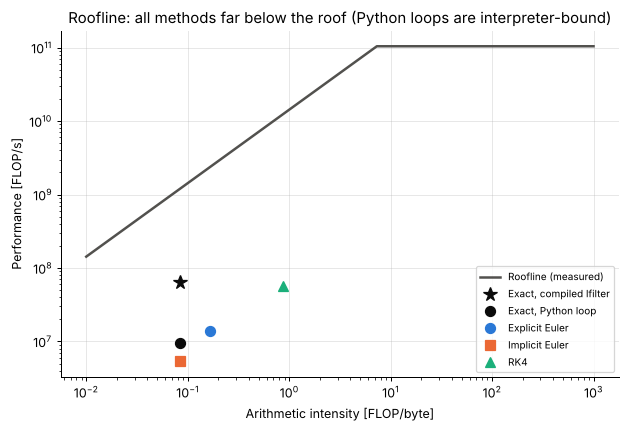

In [17]:
# Empirical roofline of this machine (Notebook 2.1.7) and where each method sits on it.
roof = empirical_roofline()
print(f"Measured peak (NumPy matmul): {roof['peak_flops'] / 1e9:.1f} GFLOP/s;  "
      f"memory bandwidth (array copy): {roof['bandwidth_bytes_per_s'] / 1e9:.1f} GB/s;  "
      f"machine balance: {roof['machine_balance']:.1f} FLOP/byte")

ai = np.logspace(-2, 3, 200)
fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(ai, np.minimum(roof["peak_flops"], roof["bandwidth_bytes_per_s"] * ai), color="#52514e", lw=2, label="Roofline (measured)")
markers = {"Exact, compiled lfilter": "*", "Exact, Python loop": "o", "Explicit Euler": "o", "Implicit Euler": "s", "RK4": "^"}
for _, row in perf.dropna(subset=["achieved FLOP/s"]).iterrows():
    color = STYLE["exact"]["color"] if row["key"] == "exact" else STYLE[row["key"]]["color"]
    ax.loglog(row["arith. intensity [FLOP/B]"], row["achieved FLOP/s"], ls="none", marker=markers[row["method"]],
              markersize=11 if "lfilter" in row["method"] else 8, color=color, label=row["method"])
ax.set_xlabel("Arithmetic intensity [FLOP/byte]")
ax.set_ylabel("Performance [FLOP/s]")
ax.set_title("Roofline: all methods far below the roof (Python loops are interpreter-bound)")
ax.legend(fontsize=8, loc="lower right")
save(fig, "stage3_roofline")

**What this shows.**

* All methods have a **low arithmetic intensity** (below 1 FLOP/byte), well under this machine's balance point. If they were written in a compiled language they would be **bandwidth-bound** (Notebook 2.1.5).
* In practice every method sits **orders of magnitude below the roofline**. The Python-loop solvers are **interpreter-bound**: almost all their time goes on Python executing each line (fetching variables, creating float objects), not on arithmetic or memory traffic. This is the interpreted-versus-compiled effect of Notebook 1.1.8. `line_profiler` confirms the time is spread across the loop's simple arithmetic lines.
* Moving the exact recurrence into compiled code (`scipy.signal.lfilter`) gives a speed-up of about 6× with identical results. The `cProfile` output shows that `lfilter` itself now takes only a few milliseconds. Most of the remaining time is NumPy array passes (exponentials, coefficients), which are memory-bound vectorised operations. Its FLOP count above includes only the 2 operations of the recurrence, not those passes. The recurrence also cannot be parallelised, because each step needs the previous result (a loop-carried dependency). This is the **optimisation adopted** for the engineering analyses. Two years of minute-by-minute CO2 now takes well under a second, so sweeps of hundreds of ventilation rates (Stage 4) and Monte Carlo samples (Stage 5) are affordable.
* SciPy's adaptive solver is the slowest by far here: the step-size controller cannot exploit any smoothness when the input changes every minute (Section D).

## K. Summary

| Check | Result |
|---|---|
| Observed convergence orders | Explicit Euler → 1, implicit Euler → 1, RK4 → 4 (Section B) |
| Decision-relevant outputs | Max 8-h mean converged to ≪ 1 ppm at the 1-minute step for every solver (C) |
| Input resolution | Coarser occupancy data hides peaks; the 8-h mean is robust; keep 1-min data (C) |
| Accuracy per cost | RK4 ≫ Euler; adaptive SciPy costly for minute-by-minute forcing (D) |
| Stability | Euler unstable for $kh>2$, RK4 for $kh>2.785$, implicit Euler unconditionally stable; G.20 at $kh = 0.03$ (E) |
| Stiffness | One eigenvalue: not stiff; implicit only needed for coarse data in small, well-ventilated rooms (F) |
| Time averaging | Exact step integral used; trapezoidal rule converges irregularly because of corners in C (G) |
| Resampling | Zero-order hold is correct for an event-driven sensor; linear interpolation changes person-time (H) |
| Numerical vs model error | Numerical error ≪ parameter uncertainty: effort belongs in sensitivity analysis (I) |
| Performance | Loop solvers interpreter-bound; compiled exact recurrence (about 6× faster) adopted (J) |

**Selected method for Stages 4–6:** the exact solution evaluated with `lfilter` (no discretisation error, fastest). RK4 and the Euler methods remain as independently verified cross-checks.

**What this notebook cannot establish:** whether the real room's CO2 follows the well-mixed model, or whether $V$, $Q$ and $G$ are correct. That requires measured CO2 (not available) and is addressed through the sensitivity analysis (Stage 5).